# **Практическая работа №4. Метод K-ближайших соседей**

Для всех классификаторов из Sklearn подбирайте лучшие гиперпараметры для модели, используя класс [GridSearchCV](https://scikit-learn.org/stable/modules/grid_search.html)

Примеры использования можно найти в технической документации, предыдущей работе, а также в следующих источниках:

[Пример 1](https://machinelearningknowledge.ai/knn-classifier-in-sklearn-using-gridsearchcv-with-example/#vii_Model_fitting_with_K-cross_Validation_and_GridSearchCV)


[Пример 2](https://vc.ru/ml/147132-kak-avtomaticheski-podobrat-parametry-dlya-modeli-mashinnogo-obucheniya-ispolzuem-gridsearchcv)

# **Базовый алгоритм KNN**

## **KNN для классификации**

### **Получение данных**

Будем работать с набором данным `iris` из `sklearn`.

In [11]:
from sklearn.datasets import load_iris
import pandas as pd


data = load_iris()

X = pd.DataFrame(data['data'], columns=data['feature_names'])
y = data['target']

X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### **1. KNN из sklearn**

#### 1.1. Разбейте данные на обучение и тест

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

#### 1.2. Обучите модель KNN

In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

a = KNeighborsClassifier()

b = {
    "n_neighbors": [1, 3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"]
}

c = GridSearchCV(a, b, cv=5)
c.fit(X_train, y_train)

model = c.best_estimator_
print(c.best_params_)

{'n_neighbors': 9, 'weights': 'uniform'}


#### 1.3. Проверьте качество работы модели

In [14]:
from sklearn.metrics import accuracy_score

a = model.predict(X_test)
print(accuracy_score(y_test, a))

0.9666666666666667


#### 1.4. Поэкспериментируйте с количеством соседей

1. Обучите модели с разным кол-вом соседей
2. Посчитайте метрику на тестовой выборке
3. Соберите данные в таблицу/график для наглядности
4. Выберите самое оптимальное значение $k$

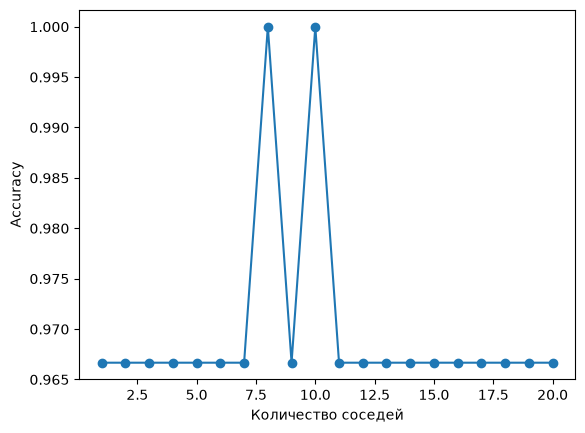

Лучшее k: 8


In [15]:
import matplotlib.pyplot as plt

a = []
b = range(1, 21)

for k in b:
    c = KNeighborsClassifier(n_neighbors=k)
    c.fit(X_train, y_train)
    a.append(c.score(X_test, y_test))

plt.plot(b, a, marker="o")
plt.xlabel("Количество соседей")
plt.ylabel("Accuracy")
plt.show()

print("Лучшее k:", b[a.index(max(a))])

### **2. KNN рукописный**

#### 2.1. Возьмите два случайных тестовых объектов

In [16]:
import numpy as np

a = np.random.choice(len(X_test), 2, replace=False)
b = X_test.iloc[a]

b

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
94,5.6,2.7,4.2,1.3
41,4.5,2.3,1.3,0.3


#### 2.2. Посчитайте для каждого расстояния до всех объектов из обучения

In [17]:
c = []

for i in range(2):
    d = np.linalg.norm(X_train.values - b.iloc[i].values, axis=1)
    c.append(d)

c

[array([3.21403174, 3.56510869, 2.50998008, 2.90172363, 3.01827765,
        0.31622777, 2.92232784, 3.33916157, 0.92736185, 3.05777697,
        2.30217289, 2.90172363, 3.07083051, 0.57445626, 1.91311265,
        3.31662479, 3.122499  , 0.54772256, 0.66332496, 0.86023253,
        3.34065862, 2.82665881, 0.77459667, 3.45543051, 2.96141858,
        2.76224546, 3.00499584, 3.04959014, 3.20936131, 1.43874946,
        3.02489669, 1.33041347, 1.1       , 1.81659021, 0.17320508,
        0.88317609, 3.10805405, 1.10905365, 0.98994949, 1.98242276,
        2.73861279, 3.19687347, 3.26802693, 1.02956301, 1.161895  ,
        1.19163753, 1.44913767, 0.33166248, 1.48660687, 3.11929479,
        2.36220236, 2.75499546, 2.74954542, 1.06770783, 1.00995049,
        0.72111026, 1.57162336, 1.21655251, 3.06267857, 2.91032644,
        1.53622915, 0.83066239, 3.56089876, 2.3515952 , 2.11187121,
        0.37416574, 1.68522995, 1.19582607, 3.01662063, 3.15277655,
        1.02956301, 0.73484692, 1.28840987, 1.1 

#### 2.3. Выберите топ $k$ соседей для каждого объекта

In [18]:
k = model.n_neighbors
d = []

for i in range(2):
    d.append(np.argsort(c[i])[:k])

d

[array([ 34, 118, 108,  97,   5,  88,  47,  65, 113]),
 array([111,   7,  85,  83,  93, 104,  36,  24, 109])]

#### 2.4. Выведите финальное предсказание для двух объектов основываясь на соседях

In [19]:
e = []

for i in range(2):
    f = y_train[d[i]]
    e.append(np.bincount(f).argmax())

print(e)

[np.int64(1), np.int64(0)]


#### 2.5. Сравните с настоящими целевыми значениями этих двух объектов

In [20]:
print("Предсказания:", e)
print("Настоящие значения:", y_test[a].tolist())

Предсказания: [np.int64(1), np.int64(0)]
Настоящие значения: [1, 0]


## **KNN для регрессии**

### Получение данных


Будем работать с набором данных для задачи регрессии - данные по предсказанию стоимости недвижимости.

In [21]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import numpy as np


data = fetch_california_housing()
X = pd.DataFrame(data['data'], columns=data['feature_names'])
y = data['target']

X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


### **KNN из sklearn**

#### 3.1. Разбейте данные на обучение и тест

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

Затем нормализуйте данные:

In [23]:
from sklearn.preprocessing import MinMaxScaler

mms = MinMaxScaler()
mms.fit(X_train)

X_train = pd.DataFrame(mms.transform(X_train[X_train.columns]), columns=X_train.columns)
X_test = pd.DataFrame(mms.transform(X_test[X_train.columns]), columns=X_train.columns)

#### 3.2. Обучите модель KNN


In [24]:
from sklearn.neighbors import KNeighborsRegressor

model = KNeighborsRegressor(n_neighbors=5)
model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


#### 3.3. Проверьте качество работы модели

In [25]:
from sklearn.metrics import mean_absolute_error, r2_score

a = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, a))
print("R2:", r2_score(y_test, a))

MAE: 0.41992443895348835
R2: 0.6954611401137232


#### 3.4. Поэкспериментируйте с количеством соседей

1. Обучите модели с разным кол-вом соседей
2. Посчитайте метрику на тестовой выборке
3. Соберите данные в таблицу/график для наглядности
4. Выберите самое оптимальное значение $k$

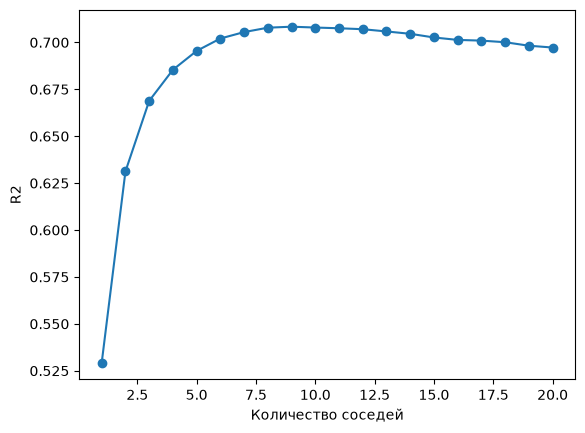

Лучшее k: 9


In [26]:
import matplotlib.pyplot as plt

a = []
b = range(1, 21)

for k in b:
    c = KNeighborsRegressor(n_neighbors=k)
    c.fit(X_train, y_train)
    a.append(c.score(X_test, y_test))

plt.plot(b, a, marker="o")
plt.xlabel("Количество соседей")
plt.ylabel("R2")
plt.show()

print("Лучшее k:", b[a.index(max(a))])

### **4. KNN рукописный**

#### 4.1. Возьмите два случайных тестовых объектов

In [27]:
a = np.random.choice(len(X_test), 2, replace=False)
b = X_test.iloc[a]

b

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
1409,0.115819,0.745098,0.021876,0.019305,0.047512,0.002826,0.154091,0.607570
4070,0.299699,0.666667,0.036309,0.023418,0.023354,0.001912,0.146652,0.601594


#### 4.2. Посчитайте для каждого расстояния до всех объектов из обучения

In [28]:
c = []

for i in range(2):
    d = np.linalg.norm(X_train.values - b.iloc[i].values, axis=1)
    c.append(d)

c

[array([0.32239167, 0.58174422, 0.77781755, ..., 0.74207346, 0.66653966,
        0.15570395], shape=(16512,)),
 array([0.34584002, 0.59221666, 0.77712055, ..., 0.55542502, 0.658802  ,
        0.07441041], shape=(16512,))]

#### 4.3. Выберите топ $k$ соседей для каждого объекта

In [29]:
k = model.n_neighbors
d = []

for i in range(2):
    d.append(np.argsort(c[i])[:k])

d

[array([13340, 13436,  7454, 15656,   757]),
 array([16191,  9197, 10900, 15143, 15937])]

#### 4.4. Выведите финальное предсказание для двух объектов основываясь на соседях

In [30]:
e = []

for i in range(2):
    e.append(y_train[d[i]].mean())

print(e)

[np.float64(1.4243999999999999), np.float64(2.4785999999999997)]


#### 4.5. Сравните с настоящими целевыми значениями этих двух объектов

In [31]:
print("Предсказания:", e)
print("Настоящие значения:", y_test[a])

Предсказания: [np.float64(1.4243999999999999), np.float64(2.4785999999999997)]
Настоящие значения: [1.079 1.464]


Предсказания отклоняются от истины, но не так сильно, они довольно близки.

# **Weighted KNN**

## **KNN для классификации**

### Получение данных

Будем работать с набором данным `iris` из `sklearn`.

In [32]:
from sklearn.datasets import load_iris
import pandas as pd


data = load_iris()

X = pd.DataFrame(data['data'], columns=data['feature_names'])
y = data['target']

X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [33]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

### Выберите только 0 и 3 признак (sepal length (cm) и petal width (cm))

In [34]:
X = X.iloc[:, [0, 3]]
X.head()

,sepal length (cm),petal width (cm)
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2


### Визуализируйте ваши данные на графике

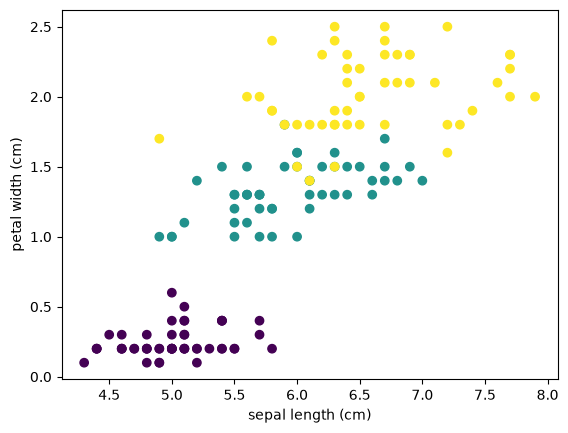

In [35]:
import matplotlib.pyplot as plt

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y)
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.show()

### **1. KNN из sklearn**

#### 1.1. Разбейте данные на обучение и тест

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

#### 1.2. Обучите модель KNN на 50 соседях

In [37]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

a = KNeighborsClassifier()

b = {
    "n_neighbors": [50],
    "weights": ["uniform"],
    "p": [1, 2]
}

c = GridSearchCV(a, b, cv=5)
c.fit(X_train, y_train)

model = c.best_estimator_
print(c.best_params_)

{'n_neighbors': 50, 'p': 1, 'weights': 'uniform'}


#### 1.3. Проверьте качество работы модели

In [38]:
from sklearn.metrics import accuracy_score

a = model.predict(X_test)
print(accuracy_score(y_test, a))

0.8666666666666667


#### 1.4. Возьмите один случайный тестовый объект и посчитайте для него расстояния до всех объектов с обучения

In [39]:
idx = np.random.randint(len(X_test))
point = X_test.iloc[idx]

dist = np.linalg.norm(X_train.values - point.values, axis=1)
dist

array([0.85440037, 0.5       , 1.14017543, 0.92195445, 1.70293864,
       2.14009346, 0.76157731, 1.1       , 0.80622577, 1.0198039 ,
       0.5       , 2.12602916, 1.84390889, 0.85440037, 1.30384048,
       0.41231056, 0.2236068 , 1.58113883, 0.5       , 1.86010752,
       0.80622577, 1.0198039 , 0.92195445, 1.44222051, 1.70293864,
       2.20227155, 0.5       , 1.25299641, 0.67082039, 0.89442719,
       1.55563492, 0.41231056, 0.2       , 0.70710678, 1.67630546,
       0.98488578, 2.33238076, 1.44222051, 0.80622577, 0.94339811,
       1.45602198, 0.67082039, 0.31622777, 1.84390889, 1.91049732,
       0.41231056, 0.82462113, 1.58113883, 1.98494332, 0.9       ,
       0.85440037, 2.30217289, 1.22065556, 2.46981781, 2.22036033,
       0.36055513, 1.98494332, 1.83847763, 1.0198039 , 1.92093727,
       0.4472136 , 2.30217289, 1.91049732, 2.14009346, 1.98494332,
       0.50990195, 1.98494332, 0.60827625, 0.50990195, 1.02956301,
       1.3       , 0.76157731, 0.70710678, 0.4472136 , 0.28284

#### 1.5. Выберите топ  k  соседей


In [40]:
k = model.n_neighbors
neighbors = np.argsort(dist)[:k]
neighbors

array([ 95,  32,  92,  16,  93,  89,  74,  42,  94, 101,  76,  55, 107,
       112,  45,  15,  31,  78,  73,  60,  10,  18,   1,  26,  65,  68,
        83,  97,  67, 100,  41, 117,  28,  33,  72, 104,  71,   6,  20,
        38,   8,  96, 118,  46, 110,  50,  13,  88,   0,  29])

#### 1.6. Выведите финальное предсказание для этого объекта

In [41]:
a = y_train[neighbors]
b = np.bincount(a).argmax()

print(b)

2


#### 1.7. Сравните с настоящим целевым значением и предсказанием модели из `sklearn`

In [42]:
print("Настоящее значение:", y_test[idx])

Настоящее значение: 1


In [43]:
print("Предсказание sklearn:", model.predict(point.to_frame().T)[0])

Предсказание sklearn: 2


#### 1.8 Визуализируйте точки с обучения и тестовую с отрисовкой ближайших соседей

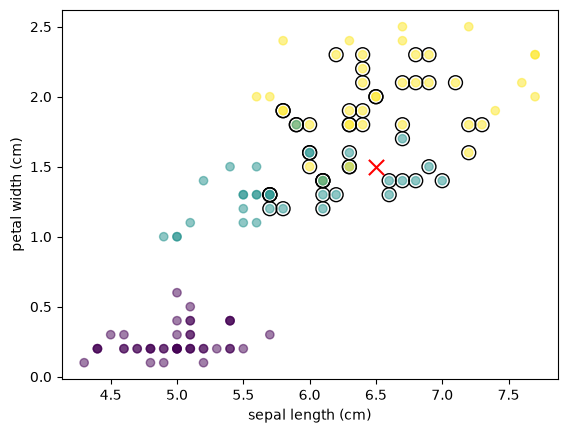

In [44]:
plt.scatter(X_train.iloc[:, 0], X_train.iloc[:, 1], c=y_train, alpha=0.5)
plt.scatter(X_train.iloc[neighbors, 0], X_train.iloc[neighbors, 1],
            facecolors="none", edgecolors="black", s=100)
plt.scatter(point.iloc[0], point.iloc[1], c="red", marker="x", s=120)
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.show()

### **2. Weighted KNN**

#### 2.1. Обучите модель "взвешенный KNN" по дистанции

In [45]:
a = KNeighborsClassifier()

params = {
    "n_neighbors": [10, 20, 30, 40, 50],
    "weights": ["distance"],
    "p": [1, 2]
}

b = GridSearchCV(a, params, cv=5)
b.fit(X_train, y_train)

model_w = b.best_estimator_
print(b.best_params_)

{'n_neighbors': 40, 'p': 1, 'weights': 'distance'}


#### 2.2. Проверьте качество работы модели


In [46]:
a = model_w.predict(X_test)
print(accuracy_score(y_test, a))

0.9333333333333333


#### 2.3. Возьмите тот же случайный тестовый объект и посчитайте для него расстояния до всех объектов с обучения

In [47]:
dist = np.linalg.norm(X_train.values - point.values, axis=1)
dist

array([0.85440037, 0.5       , 1.14017543, 0.92195445, 1.70293864,
       2.14009346, 0.76157731, 1.1       , 0.80622577, 1.0198039 ,
       0.5       , 2.12602916, 1.84390889, 0.85440037, 1.30384048,
       0.41231056, 0.2236068 , 1.58113883, 0.5       , 1.86010752,
       0.80622577, 1.0198039 , 0.92195445, 1.44222051, 1.70293864,
       2.20227155, 0.5       , 1.25299641, 0.67082039, 0.89442719,
       1.55563492, 0.41231056, 0.2       , 0.70710678, 1.67630546,
       0.98488578, 2.33238076, 1.44222051, 0.80622577, 0.94339811,
       1.45602198, 0.67082039, 0.31622777, 1.84390889, 1.91049732,
       0.41231056, 0.82462113, 1.58113883, 1.98494332, 0.9       ,
       0.85440037, 2.30217289, 1.22065556, 2.46981781, 2.22036033,
       0.36055513, 1.98494332, 1.83847763, 1.0198039 , 1.92093727,
       0.4472136 , 2.30217289, 1.91049732, 2.14009346, 1.98494332,
       0.50990195, 1.98494332, 0.60827625, 0.50990195, 1.02956301,
       1.3       , 0.76157731, 0.70710678, 0.4472136 , 0.28284

#### 2.4. Выберите топ  k  соседей


In [48]:
k = model_w.n_neighbors
neighbors = np.argsort(dist)[:k]
neighbors

array([ 95,  32,  92,  16,  93,  89,  74,  42,  94, 101,  76,  55, 107,
       112,  45,  15,  31,  78,  73,  60,  10,  18,   1,  26,  65,  68,
        83,  97,  67, 100,  41, 117,  28,  33,  72, 104,  71,   6,  20,
        38])

#### 2.5. Рассчитайте вес для каждого соседа

In [49]:
weights = 1 / (dist[neighbors] + 0.000001)
weights

array([7.07101781, 4.999975  , 4.999975  , 4.47211596, 4.47211596,
       4.47211596, 3.53552141, 3.16226766, 3.16226766, 2.77349329,
       2.77349329, 2.77349329, 2.77349329, 2.49999375, 2.42535037,
       2.42535037, 2.42535037, 2.42535037, 2.23606298, 2.23606298,
       1.999996  , 1.999996  , 1.999996  , 1.999996  , 1.96115751,
       1.96115751, 1.96115751, 1.71498291, 1.64398717, 1.58113633,
       1.49070976, 1.49070976, 1.49070976, 1.41421156, 1.41421156,
       1.38674857, 1.3130626 , 1.3130626 , 1.24034581, 1.24034581])

#### 2.6. Выведите финальное предсказание для этого объекта

In [50]:
a = y_train[neighbors]

b = []
for i in np.unique(a):
    b.append(weights[a == i].sum())

c = np.unique(a)[np.argmax(b)]
print(c)

1


#### 2.7. Сравните с настоящим целевым значением и предсказанием модели из `sklearn`

In [51]:
print("Настоящее значение:", y_test[idx])

Настоящее значение: 1


In [52]:
print("Предсказание sklearn:", model_w.predict(point.to_frame().T)[0])

Предсказание sklearn: 1


#### 2.8. Визуализируйте точки с обучения и тестовую с отрисовкой ближайших соседей по удаленности

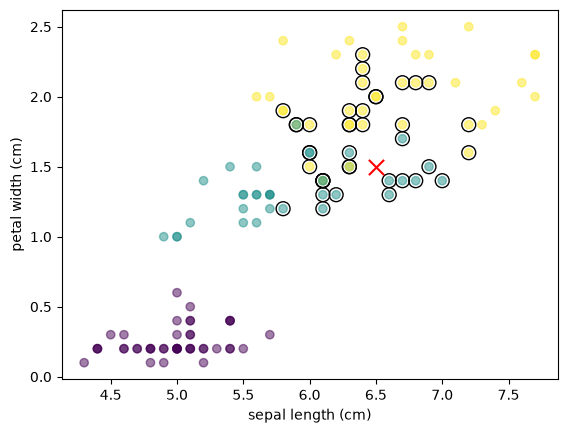

In [53]:
plt.scatter(X_train.iloc[:, 0], X_train.iloc[:, 1], c=y_train, alpha=0.5)
plt.scatter(X_train.iloc[neighbors, 0], X_train.iloc[neighbors, 1],
            facecolors="none", edgecolors="black", s=100)
plt.scatter(point.iloc[0], point.iloc[1], c="red", marker="x", s=120)
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.show()

## **KNN для регрессии**

### Получение данных


Будем работать с набором данных для задачи регрессии - данные по предсказанию стоимости недвижимости.

In [54]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import numpy as np


data = fetch_california_housing()
X = pd.DataFrame(data['data'], columns=data['feature_names'])
y = data['target']

X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [55]:
y

array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,))

### Возьмите только признак MedInc и 1000 первых строк

In [56]:
X = X[["MedInc"]].iloc[:1000]
y = y[:1000]

X.head()

,MedInc
0,8.3252
1,8.3014
2,7.2574
3,5.6431
4,3.8462


### Отрисуйте данные на графике

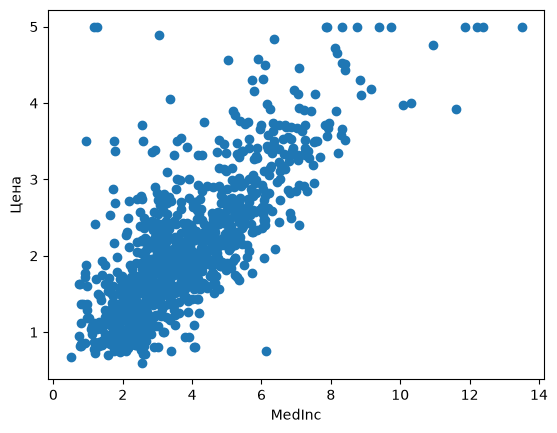

In [57]:
import matplotlib.pyplot as plt

plt.scatter(X["MedInc"], y)
plt.xlabel("MedInc")
plt.ylabel("Цена")
plt.show()

### **4. KNN из sklearn**

#### 4.1. Разбейте данные на обучение и тест

In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

#### 4.2. Обучите модель KNN на 100 соседях


In [59]:
from sklearn.neighbors import KNeighborsRegressor

model_reg = KNeighborsRegressor(n_neighbors=100)
model_reg.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",100
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


#### 4.3. Проверьте качество работы модели


In [60]:
from sklearn.metrics import mean_absolute_error, r2_score

a = model_reg.predict(X_test)

print("MAE:", mean_absolute_error(y_test, a))
print("R2:", r2_score(y_test, a))

MAE: 0.42733278249999995
R2: 0.5592926462658814


#### 4.4. Возьмите один случайный тестовый объект и посчитайте для него расстояния до всех объектов с обучения

In [61]:
idx = np.random.randint(len(X_test))
point = X_test.iloc[idx]

dist = np.linalg.norm(X_train.values - point.values, axis=1)
dist

array([3.40900e-01, 1.30620e+00, 4.54150e+00, 1.20080e+00, 4.37160e+00,
       1.11700e-01, 2.92400e+00, 2.46140e+00, 1.19040e+00, 5.61780e+00,
       6.95000e-02, 3.79360e+00, 9.54900e-01, 1.39820e+00, 7.70200e-01,
       1.99500e+00, 3.73800e-01, 1.80900e-01, 7.35400e-01, 5.96600e-01,
       7.80300e-01, 5.84900e-01, 1.47700e-01, 1.40910e+00, 3.44340e+00,
       3.59100e-01, 2.65410e+00, 2.15520e+00, 1.21140e+00, 1.45910e+00,
       1.81220e+00, 8.10000e-02, 5.68860e+00, 2.45160e+00, 7.73200e-01,
       9.29900e-01, 1.54920e+00, 1.23150e+00, 4.04400e+00, 1.90400e-01,
       7.57300e-01, 3.61430e+00, 1.45800e+00, 5.76000e-02, 5.69800e-01,
       1.42470e+00, 3.96690e+00, 2.36790e+00, 4.44400e-01, 2.85420e+00,
       1.34290e+00, 1.47880e+00, 9.04100e-01, 1.17990e+00, 9.69500e-01,
       7.60300e-01, 2.19240e+00, 1.75220e+00, 2.57230e+00, 1.63130e+00,
       2.92500e-01, 8.02800e-01, 3.14370e+00, 1.45600e+00, 3.49140e+00,
       3.94000e-02, 1.15910e+00, 2.07740e+00, 1.77000e-01, 4.659

#### 4.5. Выберите топ  k  соседей


k = model_reg.n_neighbors
neighbors = np.argsort(dist)[:k]
neighbors

In [62]:
a = y_train[neighbors].mean()
print(a)

2.21555


#### 4.7. Сравните с настоящим целевым значением и предсказанием модели из `sklearn`

In [63]:
print("Настоящее значение:", y_test[idx])

Настоящее значение: 1.014


In [64]:
print("Предсказание sklearn:", model_reg.predict(point.to_frame().T)[0])

Предсказание sklearn: 1.7015899999999997


#### 4.8 Визуализируйте точки с обучения и тестовую с отрисовкой ближайших соседей

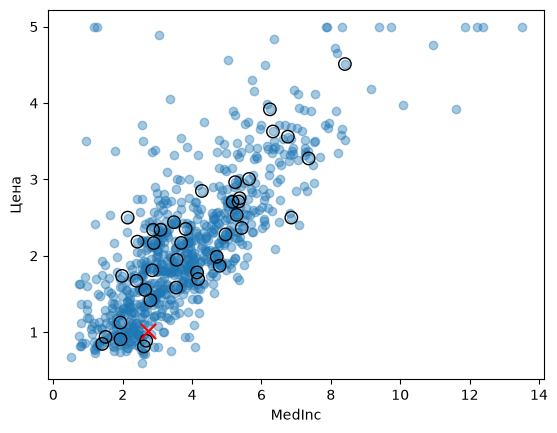

In [65]:
plt.scatter(X_train["MedInc"], y_train, alpha=0.4)
plt.scatter(X_train.iloc[neighbors]["MedInc"], y_train[neighbors],
            facecolors="none", edgecolors="black", s=80)
plt.scatter(point.iloc[0], y_test[idx], c="red", marker="x", s=120)
plt.xlabel("MedInc")
plt.ylabel("Цена")
plt.show()

### **5. Weighted KNN**

#### 5.1. Обучите модель взвешенный KNN по дистанции

In [66]:
model_w_reg = KNeighborsRegressor(n_neighbors=100, weights="distance")
model_w_reg.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",100
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


#### 5.2. Проверьте качество работы модели


In [67]:
a = model_w_reg.predict(X_test)

print("MAE:", mean_absolute_error(y_test, a))
print("R2:", r2_score(y_test, a))

MAE: 0.46599189776314676
R2: 0.4811009691491013


#### 5.3. Возьмите тот же случайный тестовый объект и посчитайте для него расстояния до всех объектов с обучения

In [68]:
dist = np.linalg.norm(X_train.values - point.values, axis=1)
dist

array([3.40900e-01, 1.30620e+00, 4.54150e+00, 1.20080e+00, 4.37160e+00,
       1.11700e-01, 2.92400e+00, 2.46140e+00, 1.19040e+00, 5.61780e+00,
       6.95000e-02, 3.79360e+00, 9.54900e-01, 1.39820e+00, 7.70200e-01,
       1.99500e+00, 3.73800e-01, 1.80900e-01, 7.35400e-01, 5.96600e-01,
       7.80300e-01, 5.84900e-01, 1.47700e-01, 1.40910e+00, 3.44340e+00,
       3.59100e-01, 2.65410e+00, 2.15520e+00, 1.21140e+00, 1.45910e+00,
       1.81220e+00, 8.10000e-02, 5.68860e+00, 2.45160e+00, 7.73200e-01,
       9.29900e-01, 1.54920e+00, 1.23150e+00, 4.04400e+00, 1.90400e-01,
       7.57300e-01, 3.61430e+00, 1.45800e+00, 5.76000e-02, 5.69800e-01,
       1.42470e+00, 3.96690e+00, 2.36790e+00, 4.44400e-01, 2.85420e+00,
       1.34290e+00, 1.47880e+00, 9.04100e-01, 1.17990e+00, 9.69500e-01,
       7.60300e-01, 2.19240e+00, 1.75220e+00, 2.57230e+00, 1.63130e+00,
       2.92500e-01, 8.02800e-01, 3.14370e+00, 1.45600e+00, 3.49140e+00,
       3.94000e-02, 1.15910e+00, 2.07740e+00, 1.77000e-01, 4.659

#### 5.4. Выберите топ  k  соседей


In [69]:
k = model_w_reg.n_neighbors
neighbors = np.argsort(dist)[:k]
neighbors

array([172, 161,  85, 722, 412, 293, 189, 300, 463, 599, 622,  65, 197,
       373, 660, 460,  43, 139, 779,  10, 362, 121, 686, 245, 571, 282,
        31, 476, 160,  96, 203, 643, 199, 179, 795, 297, 775, 661, 503,
       100,   5, 670, 709, 210, 671, 654, 154, 681, 416, 393, 117, 388,
       185, 787,  22, 739, 534, 621, 426, 177, 151,  83, 405,  98, 619,
       668, 552, 396, 264, 342, 693, 279,  68, 486, 597,  17, 748, 646,
       394, 358, 244,  39, 176,  86, 241, 228, 247, 242, 724, 356, 433,
       327, 546, 725, 702, 287, 579, 632, 421, 332])

#### 5.5. Рассчитайте вес для каждого соседа

In [77]:
weights = 1 / (dist[neighbors] + 0.000001)
weights

array([227.22108612,  71.42346975,  69.43962225,  61.7245849 ,
        51.81078701,  46.94615276,  40.81466063,  31.44555203,
        29.32465324,  28.32780941,  25.57479348,  25.3800665 ,
        23.64010307,  22.72675621,  21.05218837,  18.69123942,
        17.36080971,  16.92018748,  16.77824198,  14.38828218,
        14.26513174,  13.69844249,  13.69844249,  13.36880523,
        12.56265625,  12.42220594,  12.3455266 ,  11.68210652,
        11.53389234,  11.40237854,  11.00097909,  11.00097909,
        10.40571898,  10.35185971,  10.31981094,   9.57845231,
         9.47858314,   9.47858314,   9.45170651,   9.3895832 ,
         8.95247133,   8.8809158 ,   8.62805325,   8.60577792,
         8.43163211,   8.3611341 ,   8.18994111,   8.01918188,
         7.94274867,   7.54142126,   7.39092837,   7.33132455,
         7.1581449 ,   6.85396262,   6.77043487,   6.63565603,
         6.59191436,   6.51886233,   6.51886233,   6.51886233,
         6.51886233,   6.28531562,   6.28531562,   6.28

#### 5.6. Выведите финальное предсказание для этого объекта

In [71]:
a = np.sum(y_train[neighbors] * weights) / np.sum(weights)
print(a)

1.734887346750664


#### 5.7. Сравните с настоящим целевым значением и предсказанием модели из `sklearn`

In [72]:
print("Настоящее значение:", y_test[idx])

Настоящее значение: 1.014


In [73]:
print("Предсказание sklearn:", model_w_reg.predict(point.to_frame().T)[0])

Предсказание sklearn: 1.7349003377950958


#### 5.8. Визуализируйте точки с обучения и тестовую с отрисовкой ближайших соседей по удаленности

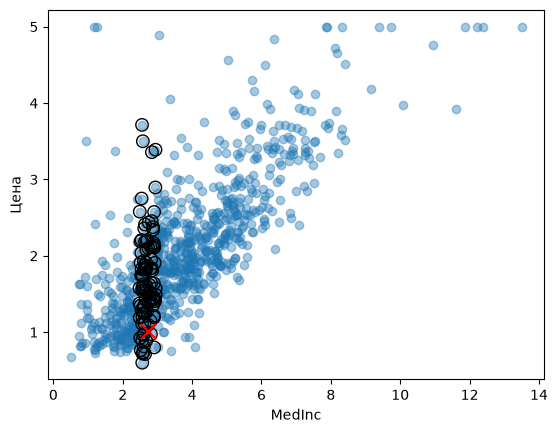

In [74]:
plt.scatter(X_train["MedInc"], y_train, alpha=0.4)
plt.scatter(X_train.iloc[neighbors]["MedInc"], y_train[neighbors],
            facecolors="none", edgecolors="black", s=80)
plt.scatter(point.iloc[0], y_test[idx], c="red", marker="x", s=120)
plt.xlabel("MedInc")
plt.ylabel("Цена")
plt.show()

## 6. Подберите лучшие гиперпараметры для последней модели, используя класс [GridSearchCV](https://scikit-learn.org/stable/modules/grid_search.html)

Примеры использования можно найти в технической документации, предыдущей работе, а также в следующих источниках:

[Пример 1](https://machinelearningknowledge.ai/knn-classifier-in-sklearn-using-gridsearchcv-with-example/#vii_Model_fitting_with_K-cross_Validation_and_GridSearchCV)


[Пример 2](https://vc.ru/ml/147132-kak-avtomaticheski-podobrat-parametry-dlya-modeli-mashinnogo-obucheniya-ispolzuem-gridsearchcv)

In [75]:
from sklearn.model_selection import GridSearchCV

a = KNeighborsRegressor()

params = {
    "n_neighbors": [5, 10, 20, 50, 100],
    "weights": ["uniform", "distance"],
    "p": [1, 2]
}

b = GridSearchCV(a, params, cv=5, scoring="r2")
b.fit(X_train, y_train)

print(b.best_params_)
print(b.best_score_)

{'n_neighbors': 50, 'p': 1, 'weights': 'uniform'}
0.5805280383673447
